# **Accreted GC vs In-Situ GC**

## *Dynamical Signature*

In-Situ
- Settled into the disk
- Orbits of lower energy
- Orbits which are prograde (rotating WITH the disk)

Accreted
- High energy
- Orbits which are retrograde (rotating OPPOSITE to the disk)

## *Spatial Oreintation*

In-Situ
- Near the centre of the glactic centre

Accreted
- Further away from the galactic centre

## *Age Metallicity Comparison*

In-Situ
- Metal rich
- Older

Accreted
- Younger
- Metal poor


Harris data notes: https://physics.mcmaster.ca/~harris/mwgc.dat\n

Vandenberg data notes: https://iopscience.iop.org/article/10.1088/0004-637X/775/2/134/pdf

String
Integers
Floats anything other than integer (decimals perhpas)
BooLean

In [10]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [11]:
# import libraries
from math import log10, floor
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colours
from astropy.io import ascii
from astropy.table import Table, join
from scipy.odr import * 

In [12]:
master_catalogue_will = ascii.read("masterv2_catalogue_will.csv", format='basic', delimiter=',', guess=False, encoding="utf-8") #specifying the format encoding="utf-8" specifies this is the way we are formating it, error popped up because of dashes in the csv for Range
master_catalogue_will

quantity,cluster_id,preferred_name,NGC,matched_to_harris,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,NGC_1,ID_1,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_2,Class,Object,AltName,Mstar,rh,C5,Age,FeH,NGC_3,NGC_4,Name_1,FeH_1,Age_1,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0
str18,str18,str11,int64,str5,str9,str11,str11,str11,float64,float64,float64,float64,float64,float64,float64,int64,str9,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,str2,str11,str11,float64,float64,float64,float64,float64,int64,int64,str5,float64,float64,float64,str1,str5,str11,float64,float64,float64,float64,float64
NGC 104,NGC 104,47 Tuc,104,True,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,104,NGC 104,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104,GC,NGC104,47Tuc,6.46,7.1,0.92,12.8,-0.76,104,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061
NGC 288,NGC 288,NGC 288,288,True,NGC 288,--,00:52:45.24,-26:34:57.4,152.3,-89.38,8.9,12.0,-0.1,0.0,-8.9,288,NGC 288,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288,GC,NGC288,Melotte3,0.46,9.8,0.05,12.2,-1.32,288,288,--,-1.32,11.5,0.38,H,24,--,0.98,12.0,-6.75,10.9,2.953
NGC 362,NGC 362,NGC 362,362,True,NGC 362,--,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,362,NGC 362,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.8,4.74,7.76,8.93,362,GC,NGC362,Dunlop62,2.5,3.5,0.72,10.0,-1.26,362,362,--,-1.3,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,4.938
Whiting 1,Whiting 1,Whiting 1,--,True,Whiting 1,--,02:02:57,-03:15:10,161.22,-60.76,30.1,34.5,-13.9,4.7,-26.3,--,Whiting 1,-130.6,1.8,-138.1,--,--,0.55,0.25,0.22,--,--,--,7.93,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
NGC 1261,NGC 1261,NGC 1261,1261,True,NGC 1261,--,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,1261,NGC 1261,68.2,4.6,54.9,--,--,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261,GC,NGC1261,Caldwell87,3.41,5.5,0.62,10.24,-1.08,1261,1261,--,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.8,23.6,3.913
Pal 1,Pal 1,Pal 1,--,True,Pal 1,--,03:33:20.04,+79:34:51.8,130.06,19.03,11.1,17.2,-6.8,8.1,3.6,--,Pal 1,-82.8,3.3,-76.2,--,--,2.57,0.01,0.46,20.93,3.51,4.06,7.76,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
AM 1,AM 1,E 1,--,True,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,--,AM 1,116.0,20.0,101.3,--,--,1.36,0.17,0.41,23.62,0.03,8.96,9.61,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
Eridanus,Eridanus,Eridanus,--,True,Eridanus,--,04:24:44.5,-21:11:13,218.1,-41.33,90.1,95.0,-53.2,-41.7,-59.5,--,Eridanus,-23.6,2.1,-39.1,--,--,1.1,0.25,0.46,22.81,0.38,9.18,9.54,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
Pal 2,Pal 2,Pal 2,--,True,Pal 2,--,04:46:05.91,+31:22:53.4,170.53,-9.07,27.2,35.0,-26.4,4.4,-4.3,--,Pal 2,-133.0,57.0,-140.1,--,--,1.53,0.17,0.5,19.06,4.06,8.82,9.28,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--


In [13]:
master_FeH = master_catalogue_will['FeH']
master_FeH

-0.76
-1.32
-1.26
--
-1.08
--
--
--
--
-1.13
-1.58


In [14]:
master_Age = master_catalogue_will['Age']
master_Age

12.8
12.2
10.0
--
10.24
--
--
--
--
7.64
12.0


In [15]:
master_R_G = master_catalogue_will['R_G']
master_R_G

7.4
12.0
9.4
--
18.1
--
--
--
--
16.6
--


/var/folders/f4/st716v0s7xx87h16gcs77fdr0000gn/T/ipykernel_30332/788153364.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  FeHvsAge = axes.scatter(master_FeH, master_Age, marker='x', s=30, cmap='viridis') # plot components


Text(0, 0.5, '$Age$, $Gyr$')

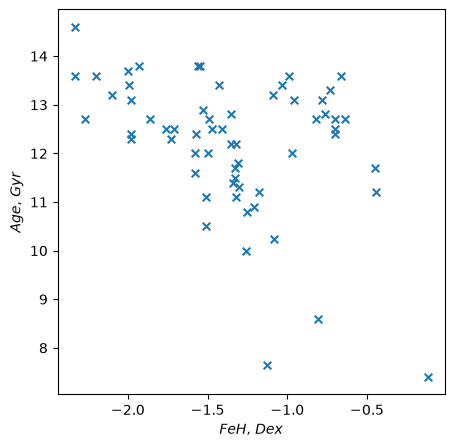

In [16]:
fig, axes = plt.subplots(1, figsize=(5,5)) #I only need one plot
FeHvsAge = axes.scatter(master_FeH, master_Age, marker='x', s=30, cmap='viridis') # plot components
axes.set_xlabel('$FeH$, $Dex$') # x-axis label
axes.set_ylabel('$Age$, $Gyr$') # y-axis label

Text(0, 0.5, '$Age$, $Gyr$')

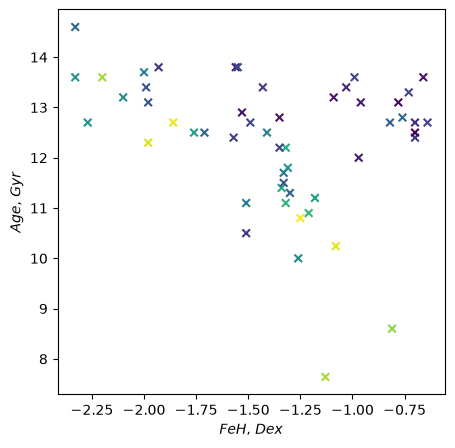

In [17]:
fig, axes = plt.subplots(1, figsize=(5,5)) #I only need one plot
FeHvsAge = axes.scatter(master_FeH, master_Age, c=master_R_G, marker='x', s=30, cmap='viridis') # plot components
axes.set_xlabel('$FeH$, $Dex$') # x-axis label
axes.set_ylabel('$Age$, $Gyr$') # y-axis label
#fig.colorbar(FeHvsAge, ax=axes[0], label = 'R_gc') not working